In [59]:
import random
import numpy as np

import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sb

import torch
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence
import torch.nn as nn
import torch.nn.functional as F

In [57]:
# define constants

BATCH_SIZE = 64
DATA_PATH = "data/en-US.jsonl"
SEED = 0
EMBEDDING_DIM = 100
HIDDEN_DIM = 128

In [52]:
# set random seeds for reproducibility

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Exploratory Data Analysis

In [3]:
# load amazon massive dataset

massive_df = pd.read_json(DATA_PATH, lines=True)
print(massive_df.head())

   id locale partition scenario             intent  \
0   0  en-US      test    alarm          alarm_set   
1   1  en-US     train    alarm          alarm_set   
2   2  en-US     train    alarm          alarm_set   
3   3  en-US      test    audio  audio_volume_mute   
4   4  en-US     train    audio  audio_volume_mute   

                                   utt  \
0      wake me up at five am this week   
1      wake me up at nine am on friday   
2  set an alarm for two hours from now   
3                                quiet   
4                           olly quiet   

                                           annot_utt  worker_id  
0  wake me up at [time : five am] [date : this week]          1  
1  wake me up at [time : nine am] on [date : friday]          1  
2       set an alarm for [time : two hours from now]          1  
3                                              quiet          1  
4                                         olly quiet          1  


In [4]:
# split by partition (train, test, validation)
# train_df is used for training, val_df is used for hyperparameter tuning, test_df is used for evaluation
train_df = massive_df[massive_df['partition'] == 'train'].reset_index(drop=True)
val_df = massive_df[massive_df['partition'] == 'dev'].reset_index(drop=True)
test_df = massive_df[massive_df['partition'] == 'test'].reset_index(drop=True)

print(f"Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}\n")

# check for data mismatch
if (len(train_df), len(val_df), len(test_df)) != (11514, 2033, 2974):
    print("\nData mismatch.")
    print(f"  • Expected: Train=11514, Val=2033, Test=2974")
    print(f"  • Received: Train={len(train_df)}, Val={len(val_df)}, Test={len(test_df)}")
    
    assert False, "Partition row counts do not match the expected dataset schema."
else:
    print("Success. All partition sizes match the benchmark exactly.")
    pass 

Train: 11514 | Val: 2033 | Test: 2974

Success. All partition sizes match the benchmark exactly.


In [5]:
# view examples of utt, intent, annot_utt

print(train_df[['utt', 'intent', 'annot_utt']].head(10))

                                            utt               intent  \
0               wake me up at nine am on friday            alarm_set   
1           set an alarm for two hours from now            alarm_set   
2                                    olly quiet    audio_volume_mute   
3                                          stop    audio_volume_mute   
4                    olly pause for ten seconds    audio_volume_mute   
5                         pause for ten seconds    audio_volume_mute   
6          make the lighting bit more warm here  iot_hue_lightchange   
7  please set the lighting suitable for reading  iot_hue_lightchange   
8                                 time to sleep     iot_hue_lightoff   
9                            time to sleep olly     iot_hue_lightoff   

                                           annot_utt  
0  wake me up at [time : nine am] on [date : friday]  
1       set an alarm for [time : two hours from now]  
2                                         

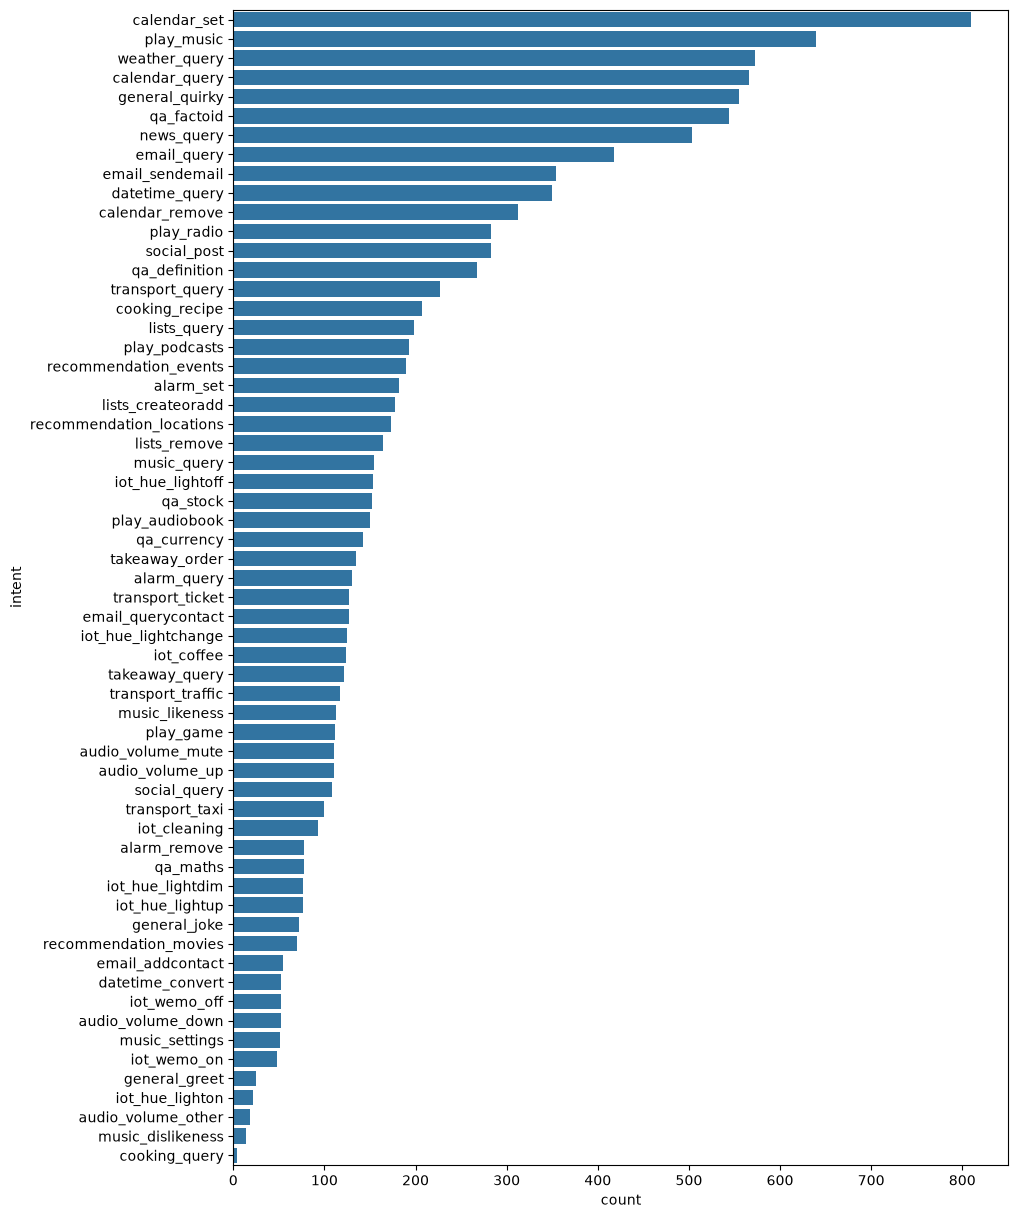

In [6]:
# check intent distribution

plt.figure(figsize=(10, 15)) 
sb.countplot(data=train_df, y='intent', order=train_df['intent'].value_counts().index)
plt.show()

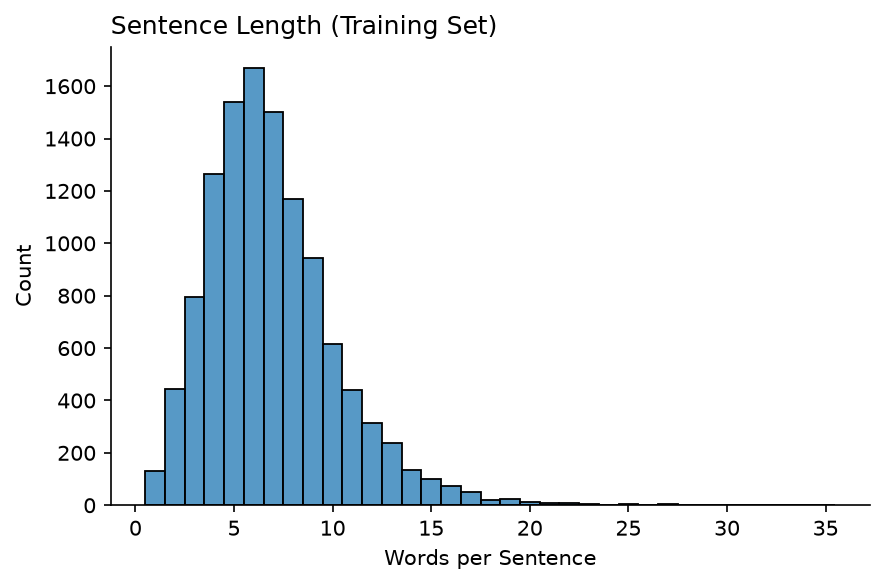

In [7]:
# get token count per entry
train_df['n_tokens'] = train_df['utt'].str.split().str.len()

# sentence length distribution
fig, ax = plt.subplots(figsize=(6, 4), dpi=150)
sb.histplot(data=train_df, x="n_tokens", ax=ax, discrete=True)
ax.set_title("Sentence Length (Training Set)", loc="left")
ax.set_xlabel("Words per Sentence")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()

In [8]:
# get all words from train place them in an array
train_words = train_df['utt'].str.split().explode()

# get unique words 
train_vocab_size = train_words.nunique()

print(f"Vocabulary Size: {train_vocab_size}")

Vocabulary Size: 5302


In [9]:
# get words in dev and test set that does not appear in train

# get all words from train place them in an array
train_vocab = set(train_df['utt'].str.split().explode())

# get all words from dev place them in an array
val_vocab = set(val_df['utt'].str.split().explode())

# get all words from test place them in an array
test_vocab = set(test_df['utt'].str.split().explode())

val_unk_words = val_vocab - train_vocab
test_unk_words = test_vocab - train_vocab

print(f"Number of unknown words in validation set: {len(val_unk_words)}")
print(f"Sample of unknown words in validation set: {list(val_unk_words)[:10]}\n")
print(f"Number of unknown words in test set: {len(test_unk_words)}")
print(f"Sample of unknown words in test set: {list(test_unk_words)[:10]}")

Number of unknown words in validation set: 439
Sample of unknown words in validation set: ['wide', 'cools', 'buble', "afi's", 'defining', 'regent', 'smashing', 'accumulated', 'natural', 'christie']

Number of unknown words in test set: 653
Sample of unknown words in test set: ['wide', "petey's", 'hometown', 'beautiful', 'conducts', 'yosemite', 'whale', 'potus', 'tessa', 'natural']


In [10]:
# count entries with no slot

no_slots_mask = ~train_df['annot_utt'].str.contains('\[', na=False)
no_slots_count = no_slots_mask.sum()
no_slots_percentage = (no_slots_count / len(train_df)) * 100

print(f"Sentences with no slots: {no_slots_count}")
print(f"Percentage of total data: {no_slots_percentage:.2f}%")

Sentences with no slots: 3755
Percentage of total data: 32.61%


<>:3: SyntaxWarning: invalid escape sequence '\['
<>:3: SyntaxWarning: invalid escape sequence '\['
/var/folders/w8/d9x92py92j792gw_1kyfc8sh0000gn/T/ipykernel_35318/1044832266.py:3: SyntaxWarning: invalid escape sequence '\['
  no_slots_mask = ~train_df['annot_utt'].str.contains('\[', na=False)


In [11]:
# count slot entries

slot_series = train_df['annot_utt'].str.findall(r'\[([a-zA-Z0-9_\-]+)\s*:')
slot_counts = slot_series.explode().value_counts()

print("----- Slot Type Counts -----")
print(slot_counts)

----- Slot Type Counts -----
annot_utt
date                    1816
place_name              1086
event_name               998
person                   864
time                     797
media_type               477
business_name            383
weather_descriptor       320
transport_type           318
food_type                295
relation                 251
timeofday                239
artist_name              232
device_type              226
definition_word          225
currency_name            217
house_place              198
list_name                191
business_type            189
news_topic               183
music_genre              181
player_setting           160
radio_name               131
song_name                128
order_type               107
color_type               100
game_name                 87
general_frequency         84
personal_info             75
audiobook_name            73
podcast_descriptor        68
meal_type                 63
playlist_name             62
time

# Pre-Processing

In [12]:
# build vocabulary. no tf-idf or bag of words as it loses word order

train_vocab_list = sorted(list(train_vocab))

word_to_idx = {"<PAD>": 0, "<UNK>": 1}
for idx, word in enumerate(train_vocab_list, start=2):
    word_to_idx[word] = idx

print(f"Vocabulary size: {len(word_to_idx)}\n")

if len(word_to_idx) != len(train_vocab_list) + 2:
    assert False, "Vocabulary size is not expected."
else:
    print("Success. Vocabulary size is as expected.")
    pass 

print(word_to_idx)

Vocabulary size: 5304

Success. Vocabulary size is as expected.
{'<PAD>': 0, '<UNK>': 1, '&': 2, '<empty>': 3, 'a': 4, 'a.': 5, 'aa': 6, 'aapa': 7, 'aaron': 8, 'abdul': 9, 'abita': 10, 'able': 11, 'abolish': 12, 'about': 13, 'above': 14, 'abraham': 15, 'abs': 16, 'absolute': 17, 'acceleration': 18, 'accept': 19, 'access': 20, 'accident': 21, 'accidents': 22, 'accommodating': 23, 'according': 24, 'accordingly': 25, 'account': 26, 'accounting': 27, 'accumulation': 28, 'acela': 29, 'acer': 30, 'achievements': 31, 'acme': 32, 'acoustic': 33, 'acoustical': 34, 'acquire': 35, 'across': 36, 'act': 37, 'action': 38, 'activate': 39, 'activated': 40, 'activates': 41, 'active': 42, 'activities': 43, 'activity': 44, 'actor': 45, 'actors': 46, 'actress': 47, 'actual': 48, 'actually': 49, 'adam': 50, 'adams': 51, 'adapt': 52, 'add': 53, 'added': 54, 'addition': 55, 'additional': 56, 'address': 57, 'addresses': 58, 'adele': 59, 'adjust': 60, 'adjustments': 61, 'administrator': 62, 'adopters': 63, 'ad

In [13]:
# encode vocabulary into integer ids

def vocab_encoding(text, vocab_dict):
    encoding_list = []
    tokens = str(text).lower().split()
    
    for token in tokens:
        if token in vocab_dict:
            integer_id = vocab_dict[token]
        else:
            integer_id = vocab_dict["<UNK>"]

        encoding_list.append(integer_id)
    return encoding_list

train_df['encoded_utt'] = train_df['utt'].apply(lambda x: vocab_encoding(x, word_to_idx))
val_df['encoded_utt'] = val_df['utt'].apply(lambda x: vocab_encoding(x, word_to_idx))
test_df['encoded_utt'] = test_df['utt'].apply(lambda x: vocab_encoding(x, word_to_idx))

print(train_df.head(10))

   id locale partition scenario               intent  \
0   1  en-US     train    alarm            alarm_set   
1   2  en-US     train    alarm            alarm_set   
2   4  en-US     train    audio    audio_volume_mute   
3   5  en-US     train    audio    audio_volume_mute   
4   6  en-US     train    audio    audio_volume_mute   
5   7  en-US     train    audio    audio_volume_mute   
6   9  en-US     train      iot  iot_hue_lightchange   
7  10  en-US     train      iot  iot_hue_lightchange   
8  12  en-US     train      iot     iot_hue_lightoff   
9  13  en-US     train      iot     iot_hue_lightoff   

                                            utt  \
0               wake me up at nine am on friday   
1           set an alarm for two hours from now   
2                                    olly quiet   
3                                          stop   
4                    olly pause for ten seconds   
5                         pause for ten seconds   
6          make the lighti

In [14]:
# perform bio tagging to identify slots

def bio_tagging(annot_utt):
    tokens = []
    bio_tags = []
    
    current_label = "O"
    is_inside_entity = False
    is_first_word = False
    
    for piece in annot_utt.split():
        if piece.startswith("["):
            current_label = piece[1:] # remove open bracket
            is_inside_entity = True
            is_first_word = True
            continue
            
        if piece == ":":
            continue
            
        has_closing = False
        if piece.endswith("]"):
            piece = piece[:-1] # remove close bracket
            has_closing = True
            
        if is_inside_entity:
            if is_first_word:
                tag = f"B-{current_label}" 
            else: 
                tag = f"I-{current_label}"
            is_first_word = False
        else:
            tag = "O"
            
        tokens.append(piece)
        bio_tags.append(tag)
        
        if has_closing:
            is_inside_entity = False
            current_label = "O"
            
    return pd.Series({"tokens": tokens, "bio_tags": bio_tags})

train_df[["tokens", "bio_tags"]] = train_df["annot_utt"].apply(lambda x: bio_tagging(x))
val_df[["tokens", "bio_tags"]] = val_df["annot_utt"].apply(lambda x: bio_tagging(x))
test_df[["tokens", "bio_tags"]] = test_df["annot_utt"].apply(lambda x: bio_tagging(x))

In [15]:
print(train_df[["annot_utt", "tokens", "bio_tags"]].head())

                                           annot_utt  \
0  wake me up at [time : nine am] on [date : friday]   
1       set an alarm for [time : two hours from now]   
2                                         olly quiet   
3                                               stop   
4                olly pause for [time : ten seconds]   

                                         tokens  \
0      [wake, me, up, at, nine, am, on, friday]   
1  [set, an, alarm, for, two, hours, from, now]   
2                                 [olly, quiet]   
3                                        [stop]   
4              [olly, pause, for, ten, seconds]   

                                       bio_tags  
0       [O, O, O, O, B-time, I-time, O, B-date]  
1  [O, O, O, O, B-time, I-time, I-time, I-time]  
2                                        [O, O]  
3                                           [O]  
4                     [O, O, O, B-time, I-time]  


In [16]:
# validate token and tag lengths

dataframes = {
    "Train": train_df,
    "Validation": val_df,
    "Test": test_df
}

for name, df in dataframes.items():
    token_length = df["encoded_utt"].apply(len)
    tag_length = df["bio_tags"].apply(len)

    mismatched_rows = df[token_length != tag_length]

    if not mismatched_rows.empty:
        print(mismatched_rows)
        assert False, f"Mismatch found in {name} split."
    else:
        print(f"{name} split passed. Token lengths equal tag lengths.")

Train split passed. Token lengths equal tag lengths.
Validation split passed. Token lengths equal tag lengths.
Test split passed. Token lengths equal tag lengths.


In [17]:
# build bio tag vocabulary

biotag_vocab_list = sorted(train_df['bio_tags'].explode().unique())

biotag_vocab_list_clean = biotag_vocab_list.copy()
biotag_vocab_list_clean.remove('O')

tag_to_idx = {"O": 0}
for idx, word in enumerate(biotag_vocab_list_clean, start=1):
    tag_to_idx[word] = idx

print(f"Vocabulary size: {len(tag_to_idx)}\n")

print(tag_to_idx)

Vocabulary size: 107

{'O': 0, 'B-alarm_type': 1, 'B-app_name': 2, 'B-artist_name': 3, 'B-audiobook_author': 4, 'B-audiobook_name': 5, 'B-business_name': 6, 'B-business_type': 7, 'B-change_amount': 8, 'B-coffee_type': 9, 'B-color_type': 10, 'B-cooking_type': 11, 'B-currency_name': 12, 'B-date': 13, 'B-definition_word': 14, 'B-device_type': 15, 'B-drink_type': 16, 'B-email_address': 17, 'B-email_folder': 18, 'B-event_name': 19, 'B-food_type': 20, 'B-game_name': 21, 'B-game_type': 22, 'B-general_frequency': 23, 'B-house_place': 24, 'B-ingredient': 25, 'B-joke_type': 26, 'B-list_name': 27, 'B-meal_type': 28, 'B-media_type': 29, 'B-movie_name': 30, 'B-movie_type': 31, 'B-music_album': 32, 'B-music_descriptor': 33, 'B-music_genre': 34, 'B-news_topic': 35, 'B-order_type': 36, 'B-person': 37, 'B-personal_info': 38, 'B-place_name': 39, 'B-player_setting': 40, 'B-playlist_name': 41, 'B-podcast_descriptor': 42, 'B-podcast_name': 43, 'B-radio_name': 44, 'B-relation': 45, 'B-song_name': 46, 'B-spo

In [23]:
# build intent vocabulary

intent_vocab_list = sorted(train_df['intent'].explode().unique())

intent_to_idx = {}
for idx, word in enumerate(intent_vocab_list, start=0):
    intent_to_idx[word] = idx

print(f"Vocabulary size: {len(intent_to_idx)}\n")

print(intent_to_idx)

Vocabulary size: 60

{'alarm_query': 0, 'alarm_remove': 1, 'alarm_set': 2, 'audio_volume_down': 3, 'audio_volume_mute': 4, 'audio_volume_other': 5, 'audio_volume_up': 6, 'calendar_query': 7, 'calendar_remove': 8, 'calendar_set': 9, 'cooking_query': 10, 'cooking_recipe': 11, 'datetime_convert': 12, 'datetime_query': 13, 'email_addcontact': 14, 'email_query': 15, 'email_querycontact': 16, 'email_sendemail': 17, 'general_greet': 18, 'general_joke': 19, 'general_quirky': 20, 'iot_cleaning': 21, 'iot_coffee': 22, 'iot_hue_lightchange': 23, 'iot_hue_lightdim': 24, 'iot_hue_lightoff': 25, 'iot_hue_lighton': 26, 'iot_hue_lightup': 27, 'iot_wemo_off': 28, 'iot_wemo_on': 29, 'lists_createoradd': 30, 'lists_query': 31, 'lists_remove': 32, 'music_dislikeness': 33, 'music_likeness': 34, 'music_query': 35, 'music_settings': 36, 'news_query': 37, 'play_audiobook': 38, 'play_game': 39, 'play_music': 40, 'play_podcasts': 41, 'play_radio': 42, 'qa_currency': 43, 'qa_definition': 44, 'qa_factoid': 45, 'q

In [18]:
# get oov rate for words

word_to_idx_keyset = set(word_to_idx.keys())
unseen_list = []

for name, df in [("Validation", val_df), ("Test", test_df)]:
    unseen = set()
    
    for token_list in df["tokens"]:
        for token in token_list:
            if token not in word_to_idx_keyset:
                unseen.add(token)
                
    if unseen:
        print(f"{name} unseen words sample: {sorted(unseen)[:10]}\n")
    else:
        print(f"All words in {name} exist in word_to_idx.")
    unseen_list.append(unseen)

val_oov_rate = (len(unseen_list[0]) / len(val_vocab)) * 100
print(f"Validation OOV Rate (Unique): {val_oov_rate:.2f}%\n")

test_oov_rate = (len(unseen_list[1]) / len(test_vocab)) * 100
print(f"Test OOV Rate (Unique): {test_oov_rate:.2f}%")

Validation unseen words sample: ['aamir', 'aaronson', 'abuse', 'academy', 'accounts', 'accumulated', 'actions', 'activation', 'acts', 'adel']

Test unseen words sample: ['abbas', 'aberdeen', 'abouts', 'academy', 'aces', 'achieve', 'acted', 'acting', 'actions', 'adding']

Validation OOV Rate (Unique): 20.62%

Test OOV Rate (Unique): 24.50%


In [19]:
# check for tags in validation and test that is not in train

tag_to_idx_keyset = set(tag_to_idx.keys())

for name, df in [("Validation", val_df), ("Test", test_df)]:
    unseen = {}
    
    for tag_list in df["bio_tags"]:
        for tag in tag_list:
            if tag not in tag_to_idx_keyset:
                if tag in unseen:
                    unseen[tag] += 1
                else:
                    unseen[tag] = 1
                
    if unseen:
        print(f"{name} unseen tags counts: {unseen}\n")
    else:
        print(f"All tags in {name} exist in tag_to_idx.\n")

All tags in Validation exist in tag_to_idx.

Test unseen tags counts: {'I-transport_type': 1}



In [25]:
# check for intent in validation and test that is not in train

intent_to_idx_keyset = set(intent_to_idx.keys())

for name, df in [("Validation", val_df), ("Test", test_df)]:
    unseen = {}
    
    for intent in df["intent"]:
        if intent not in intent_to_idx_keyset:
            if intent in unseen:
                unseen[intent] += 1
            else:
                unseen[intent] = 1
                
    if unseen:
        print(f"{name} unseen intent counts: {unseen}\n")
    else:
        print(f"All intents in {name} exist in intent_to_idx.\n")

All intents in Validation exist in intent_to_idx.

All intents in Test exist in intent_to_idx.



In [29]:
# append tag_id, intent_id to dataframes

dataframes = {
    "Train": train_df,
    "Validation": val_df,
    "Test": test_df
}

for name, df in dataframes.items():
    df["tag_ids"] = df["bio_tags"].apply(
        lambda tags: [tag_to_idx.get(tag, 0) for tag in tags]
    )

    df["intent_id"] = df["intent"].apply(
        lambda intent: intent_to_idx.get(intent)
    )

In [31]:
print(train_df)

          id locale partition scenario              intent  \
0          1  en-US     train    alarm           alarm_set   
1          2  en-US     train    alarm           alarm_set   
2          4  en-US     train    audio   audio_volume_mute   
3          5  en-US     train    audio   audio_volume_mute   
4          6  en-US     train    audio   audio_volume_mute   
...      ...    ...       ...      ...                 ...   
11509  17175  en-US     train    email  email_querycontact   
11510  17176  en-US     train    email         email_query   
11511  17177  en-US     train    email         email_query   
11512  17178  en-US     train    email         email_query   
11513  17180  en-US     train    email         email_query   

                                       utt  \
0          wake me up at nine am on friday   
1      set an alarm for two hours from now   
2                               olly quiet   
3                                     stop   
4               olly paus

In [30]:
print(val_df)

         id locale partition scenario              intent  \
0        11  en-US       dev      iot    iot_hue_lightoff   
1        17  en-US       dev      iot    iot_hue_lightdim   
2        24  en-US       dev      iot    iot_hue_lightdim   
3        26  en-US       dev      iot        iot_cleaning   
4        30  en-US       dev      iot        iot_cleaning   
...     ...    ...       ...      ...                 ...   
2028  17121  en-US       dev    email         email_query   
2029  17137  en-US       dev    email         email_query   
2030  17140  en-US       dev    email     email_sendemail   
2031  17153  en-US       dev    email         email_query   
2032  17167  en-US       dev    email  email_querycontact   

                                                    utt  \
0                            turn the lights off please   
1                            dim the lights in the hall   
2                                    make a room darker   
3                              

In [32]:
print(test_df)

         id locale partition scenario               intent  \
0         0  en-US      test    alarm            alarm_set   
1         3  en-US      test    audio    audio_volume_mute   
2         8  en-US      test      iot  iot_hue_lightchange   
3        14  en-US      test      iot      iot_hue_lighton   
4        19  en-US      test      iot     iot_hue_lightoff   
...     ...    ...       ...      ...                  ...   
2969  17151  en-US      test    email      email_sendemail   
2970  17156  en-US      test    email          email_query   
2971  17157  en-US      test    email          email_query   
2972  17170  en-US      test    email          email_query   
2973  17179  en-US      test    email          email_query   

                                                    utt  \
0                       wake me up at five am this week   
1                                                 quiet   
2                                   pink is all we need   
3                  

In [43]:
# convert df to pytorch ds

class CustomMassiveDataset(Dataset):                      
    def __init__(self, df):
        self.df = df  

    def __len__(self):                                 
        return len(self.df)                     

    def __getitem__(self, idx):                            
        encoded_utt = torch.tensor(self.df.iloc[idx]["encoded_utt"])      
        tag_ids = torch.tensor(self.df.iloc[idx]["tag_ids"])
        intent_id = torch.tensor(self.df.iloc[idx]["intent_id"])         
        return encoded_utt, tag_ids, intent_id

train_ds = CustomMassiveDataset(train_df)
val_ds   = CustomMassiveDataset(val_df)
test_ds  = CustomMassiveDataset(test_df)

print(len(train_ds), len(val_ds), len(test_ds))
print()
print(train_ds[0])

11514 2033 2974

(tensor([5077, 2875, 4987,  278, 3162,  139, 3266, 1815]), tensor([  0,   0,   0,   0,  48, 100,   0,  13]), tensor(2))


In [46]:
# pad tensors, match tensor dimensions

def collate_batch(batch):
    word_list = []
    tag_list = []
    intent_list = []

    # separate to three lists, words, tags, intents
    for word, tag, intent in batch:
        word_list.append(word)
        tag_list.append(tag)
        intent_list.append(intent)
    
    # pad the words list with 0 
    word_pads = pad_sequence(word_list, batch_first=True, padding_value=0)
        
    # pad the tags list with -100. 0 means outside.
    tag_pads = pad_sequence(tag_list, batch_first=True, padding_value=-100)
    
    # stack the intents          
    intent_stack = torch.stack(intent_list)
    
    return word_pads, tag_pads, intent_stack

In [55]:
# build dataloader

train_dl = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_batch)
val_dl = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_batch)
test_dl = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_batch)

In [66]:
words, tags, intents = next(iter(train_dl))
print(words[:2])
print(tags[:2])      
print(intents[:2])

tensor([[1230, 4741, 1364, 2669, 1761, 2875,    0,    0,    0,    0,    0,    0,
            0,    0,    0,    0,    0,    0],
        [5157, 5241,   76, 2708, 2649, 2237, 4714, 5267,    0,    0,    0,    0,
            0,    0,    0,    0,    0,    0]])
tensor([[   0,    0,   27,   79,    0,    0, -100, -100, -100, -100, -100, -100,
         -100, -100, -100, -100, -100, -100],
        [   0,    0,   39,    0,    0,    0,    0,    0, -100, -100, -100, -100,
         -100, -100, -100, -100, -100, -100]])
tensor([32, 20])


In [56]:
# data processing

# iter preps dataloader to divide data into batches. next gets first batch
words, tags, intents = next(iter(train_dl))
print(words.shape, tags.shape, intents.shape)

torch.Size([64, 16]) torch.Size([64, 16]) torch.Size([64])


# Building The Model

### Independent Baseline

**Model Justification**
- LSTM is chosen because it retains semantic information, meaning, context across words in a sentence by combining long-term cell state and short-term memory.
- RNNs do not have gates and only preserve one hidden state, storing less context than LSTMs and suffering from vanishing gradient, despite being faster and simpler.
- Transformers would potentially outperform LSTMs as it uses self-attention, allowing it to process entire sequence at once, capturing long-range context better. However, the MASSIVE dataset is likely too small to perform well for a transformer trained from scratch. Whilst it suffices for pre-trained models like BERT, it is not allowed. Also harder to use due to hyperparameters, more difficult to train vs LSTMs.
- 1D CNN uses n-grams sliding windows. It allows for parallel computing and efficient for capturing local key features but lacks recurrent architecture, making it poorer in tracking semantic dependencies and context over longer-range dependencies within sentences. 

**Architecture**
- Embedding layer. EMBEDDING_DIM provides per word dimension, <PAD> embeddings uses 0,  size is given by vocab_size x EMBEDDING_DIM.
- 1-layer unidirectional LSTM with size of hidden state given by HIDDEN_DIM, shared by both tasks
- Tag head. Produces a score across all 107 tags. Reads from hidden state at every word. 
- Intent head. Extracts 60 scores across all intents. Reads hidden state after last word.

**Inputs**
- Padded word ids, shape [batch, seq_len]

**Outputs**
- Tag scores [batch, seq_len, no_of_tags] (one per word)
- Intent scores [batch, no_of_intents] (one per sentence)

**Loss**
- Cross-entropy is performed across both tag and intent for loss functions. Total loss is given by the sum of tag loss and intent loss.
- Tag loss skips padding spots set to -100.
- Cross-entropy is able to give useful gradients as it incorporates log_softmax function, making for stronger gradients, prompting for more learning.
- Cross-entropy is also suitable for selecting best performer across a set of options i.e. tags, intents.

**Optimizer**
- ... (e.g. Adam, learning rate ...)

In [60]:
class CustomMassiveModel(nn.Module):
    def __init__(self, embedding_dim, hidden_dim, vocab_size, num_tags, num_intent):
        super().__init__()
        self.hidden_dim = hidden_dim
        self.word_embeddings = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        self.lstm = nn.LSTM(embedding_dim, hidden_dim, batch_first = True)

    def forward(self, sentence):
        embeds = self.word_embeddings(sentence)
        lstm_out, (h, c) = self.lstm(embeds)
        tag_space = self.hidden2tag(lstm_out)
        intent_space = self.hidden2intent(h[-1]) # feed output of tag head
        
        return tag_space, intent_space

model = CustomMassiveModel(EMBEDDING_DIM, HIDDEN_DIM, len(word_to_idx), len(tag_to_idx), len(intent_to_idx))
words, tags, intents = next(iter(train_dl))
tag_scores, intent_scores = model(words)
print(tag_scores.shape, intent_scores.shape)

torch.Size([64, 15, 107]) torch.Size([64, 60])


In [75]:
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Total parameters (includes embedding layer/word vectors): {total_params:,}")
print(f"Total trainable parameters: {trainable_params:,}")

if total_params < 20_000_000:
    print(f"Parameter count is within range, {total_params:,} < 20,000,000.")
else:
    assert False, f"Parameter count exceeded range, {total_params:,} > 20,000,000."

Total parameters (includes embedding layer/word vectors): 669,703
Total trainable parameters: 669,703
Parameter count is within range, 669,703 < 20,000,000.
